In [34]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator
from scipy.signal import find_peaks


plt.rcParams.update({
    'font.family':'serif',
    'font.serif':'Times New Roman',
    'font.size': 16,        # Default text size
    'axes.titlesize': 18,   # Title size
    'axes.labelsize': 18,   # X and Y axis label size
    'xtick.labelsize': 16,  # X tick label size
    'ytick.labelsize': 16,  # Y tick label size
    'legend.fontsize': 16,  # Legend font size
    'figure.titlesize': 20  # Figure-level title size
})


In [2]:
nest_depth = 0.6                                                                                # m
well_offsets = {'A1': -1.657, 'B1': 0.888, 'B2': 1.602, 'B3': 0.043}                            # cmH2O, "A2": 1.602 REMOVED
baro_offset = -0.875                                                                            # cmH2O

well_z = {'A1': 3.455, 'B1': 2.820,'B2': 2.752, 'B3': 2.252}                                   # m, "A2": 4.076 REMOVED
well_b = {'A1': 0.490, 'B1': 0.400, 'B2': 0.442, 'B3': 0.334}                                       # m, "A2": 0 REMOVED
well_toc = {k: well_z[k] + well_b[k] for k in well_z}                                           # m
CL = 2.044 - 0.097 - 0.100                                                                      # m

well_x = {'B1': 36.7, 'B2': 45.7, 'B3': 54.8}
wellA_x = {'A1': 24.2}

max_jump = 0.5
max_interp_points = int(pd.Timedelta(hours=6) / pd.Timedelta(minutes=10))

colours = ['#0a91a1', '#74c9b9','#f47c53', '#f8a953']

In [3]:
folder = Path("../data/groundwater/DiverCSV")

def read_diver(file):
    df = pd.read_csv(file, skiprows=51, sep=",", encoding="cp1252", usecols=[0, 1])[:-1]
    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    return df.dropna().sort_values("Date/time")

files = [f for f in folder.glob("*.CSV") if f.stem.split("_")[0] in well_offsets]
all_divers = pd.concat([read_diver(f).assign(Diver=f.stem.split("_")[0]) for f in files], ignore_index=True)
all_divers['Pressure[mH2O]'] = (all_divers['Pressure[cmH2O]'] - all_divers['Diver'].map(well_offsets)) / 100

baro = read_diver(next(folder.glob("Baro*.CSV")))
baro['Pressure[mH2O]'] = (baro['Pressure[cmH2O]'] - baro_offset) / 100

tranA = pd.read_csv('../data/groundwater/wellA_transect_profile.csv')
tranA['z'] = tranA[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

tranB = pd.read_csv('../data/groundwater/well_transect_profile.csv')
tranB['z'] = tranB[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

raw_tides = pd.read_csv('../data/water_levels/QUINTA_water_levels_fieldwork_2026.csv', usecols=['dates', 'water_level_egm2008'])

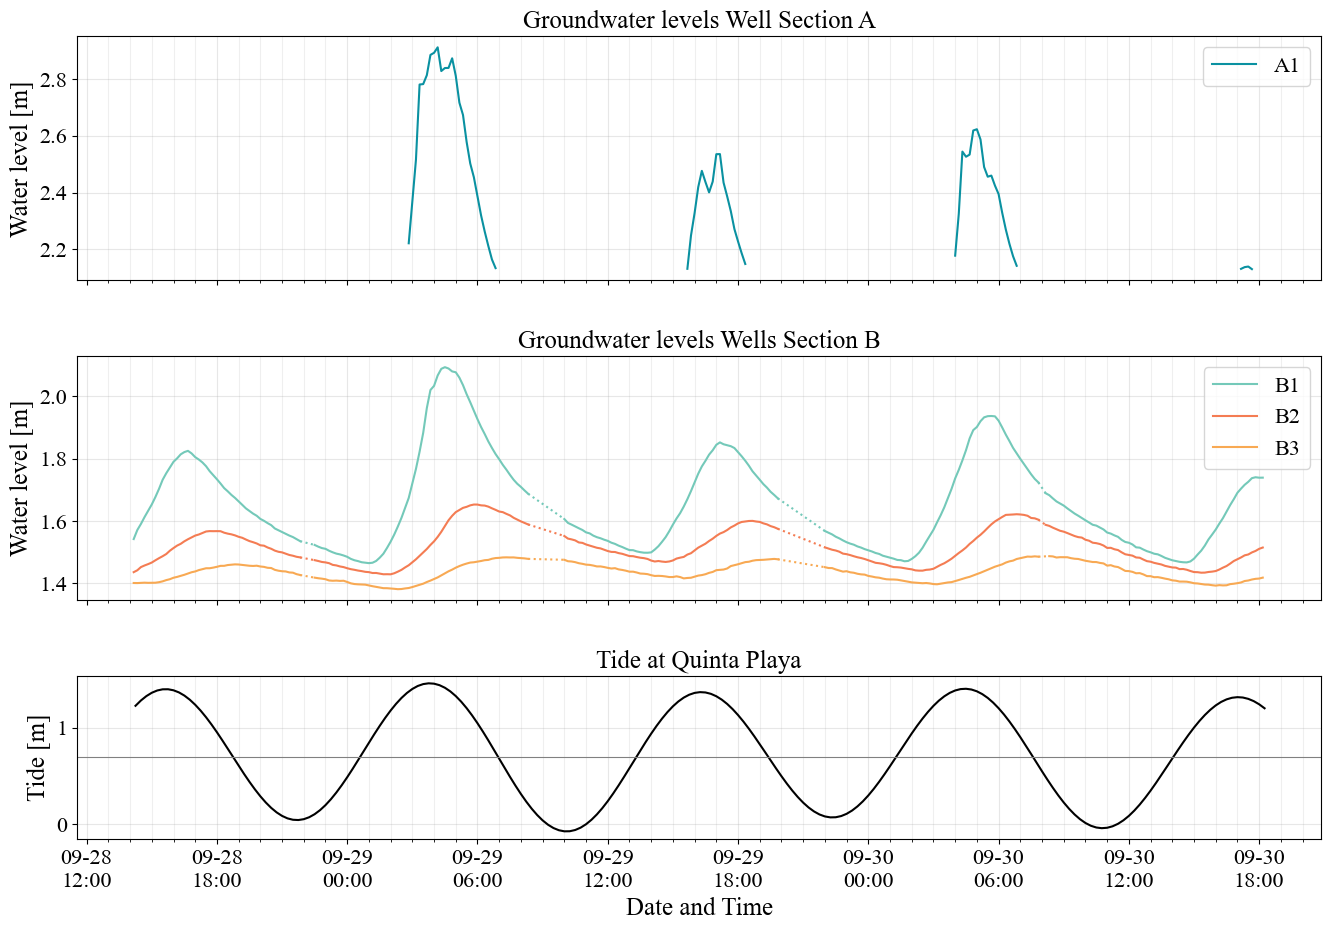

In [46]:
start = '2026-09-28 14:15:00'
end = '2026-09-30 18:15:00'

baro_at_diver_time = np.interp(all_divers['Date/time'].astype('int64'), baro['Date/time'].astype('int64'), baro['Pressure[mH2O]'])

all_divers['WC'] = all_divers['Pressure[mH2O]'] - baro_at_diver_time
all_divers['WL'] = all_divers['Diver'].map(well_toc) - CL + all_divers['WC']
wl = all_divers.loc[all_divers['Date/time'].between(start, end) & (all_divers['WC'] > 0.03)].copy()

tides = raw_tides.copy()
tides['dates'] = pd.to_datetime(tides['dates'], utc=True).dt.tz_localize(None) + pd.Timedelta(hours=-6)
tides = tides.loc[tides['dates'].between(start, end)].copy()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 3, 2]})

well_colours = {name: colours[i % len(colours)] for i, name in enumerate(sorted(wl['Diver'].unique()))}
well_axes = {'A': ax1, 'B': ax2}

for name, df in wl.groupby("Diver"):
    s = df.set_index('Date/time')['WL'].resample('10min').mean()
    med = s.rolling(7, center=True, min_periods=3).median()
    s[(s - med).abs() > max_jump] = np.nan
    ax = well_axes.get(name[0])
    color = well_colours[name]
    ax.plot(s.index.to_numpy(), s.to_numpy(), label=name, color=color, linewidth=1.5)
    
    if name[0] != 'A':
        interpolated = s.interpolate(method='time', limit=max_interp_points, limit_area='inside')
        gap = s.isna() & interpolated.notna()
        bridge = interpolated.where(gap | gap.shift(1, fill_value=False) | gap.shift(-1, fill_value=False))
        ax.plot(bridge.index.to_numpy(), bridge.to_numpy(), color=color, linestyle=':', linewidth=1.5)


ax1.set_ylabel('Water level [m]')
ax1.set_title('Groundwater levels Well Section A')
ax1.legend()

ax2.set_ylabel('Water level [m]')
ax2.set_title('Groundwater levels Wells Section B')
ax2.legend()

ax3.plot(tides["dates"].to_numpy(), tides['water_level_egm2008'].to_numpy(), color='k', linewidth=1.5)
ax3.axhline(0.7, color='gray', lw=0.8)
ax3.set_title('Tide at Quinta Playa')
ax3.set_ylabel('Tide [m]')
ax3.set_xlabel('Date and Time')

ax3.xaxis.set_major_locator(mdates.AutoDateLocator())
ax3.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
fig.tight_layout(pad=2)

for ax in (ax1, ax2, ax3):
    ax.grid(alpha=0.3)
    ax.grid(which='minor', axis='x', alpha=0.2)


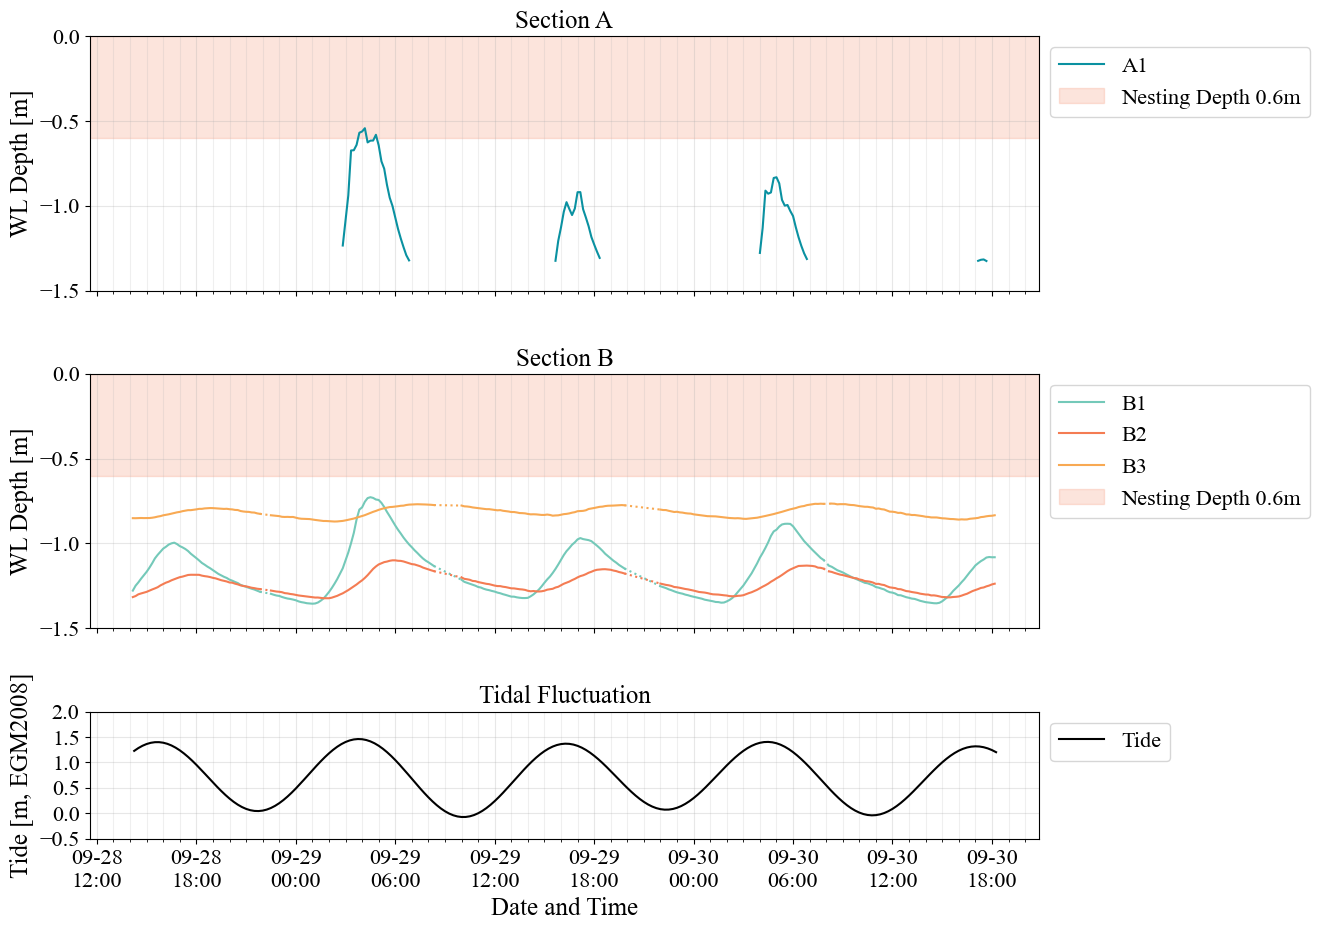

In [33]:
all_divers['c'] = all_divers['WL'] - all_divers['Diver'].map(well_z)
c = all_divers.loc[all_divers['Date/time'].between(start, end) & (all_divers['WC'] > 0.03)].copy()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.5]})

well_colours = {name: colours[i % len(colours)] for i, name in enumerate(sorted(c['Diver'].unique()))}
well_axes = {'A': ax1, 'B': ax2}

for name, df in c.groupby("Diver"):
    s = df.set_index('Date/time')['c'].resample('10min').mean()
    med = s.rolling(7, center=True, min_periods=3).median()
    s[(s - med).abs() > max_jump] = np.nan
    ax = well_axes.get(name[0])
    color = well_colours[name]
    ax.plot(s.index.to_numpy(), s.to_numpy(), label=name, color=color, linewidth=1.5)
    
    if name[0] != 'A':
        interpolated = s.interpolate(method='time', limit=max_interp_points, limit_area='inside')
        gap = s.isna() & interpolated.notna()
        bridge = interpolated.where(gap | gap.shift(1, fill_value=False) | gap.shift(-1, fill_value=False))
        ax.plot(bridge.index.to_numpy(), bridge.to_numpy(), color=color, linestyle=':', linewidth=1.5)

titles = ['A', 'B']

for i, ax in enumerate((ax1, ax2)):
    ax.set_title(f'Section {titles[i]}')
    ax.axhspan(-nest_depth, 0, color='#f47c53', alpha=0.2, label=f'Nesting Depth {nest_depth}m')
    ax.set_ylabel('WL Depth [m]')
    ax.set_ylim(ymin=-1.5, ymax=0)
    ax.grid(alpha=0.3)
    ax.grid(which='minor', axis='x', alpha=0.2)
    ax.legend(bbox_to_anchor=(1, 1), loc='upper left')

ax3.plot(tides['dates'], tides['water_level_egm2008'], color='k', linewidth=1.5, label='Tide')
ax3.legend(bbox_to_anchor=(1, 1), loc='upper left')
ax3.set_ylim(ymin=-0.5, ymax=2)
ax3.set_title('Tidal Fluctuation')
ax3.set_ylabel('Tide [m, EGM2008]')
ax3.set_xlabel('Date and Time')
ax3.grid(alpha=0.3)
ax3.grid(which='minor', axis='x', alpha=0.2)

ax3.yaxis.set_major_locator(MultipleLocator(0.5))
ax3.xaxis.set_major_locator(mdates.AutoDateLocator())
ax3.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
fig.tight_layout(pad=2)

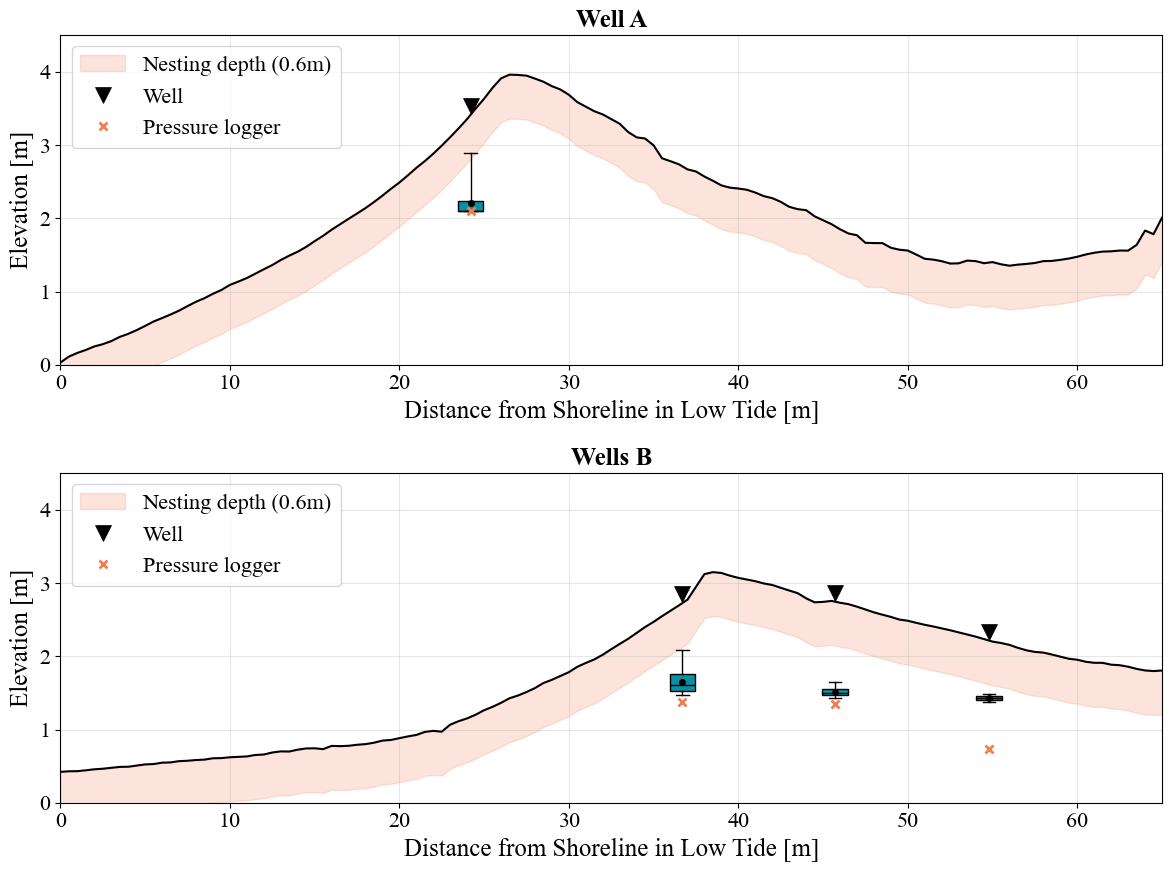

In [68]:
sensor_z = {w: well_toc[w] - CL for w in well_toc}

box_style = dict(whis=(1, 99), showfliers=False, showmeans=True, patch_artist=True, manage_ticks=False,
                 boxprops=dict(facecolor='#0a91a1'), medianprops=dict(color='k'),
                 meanprops=dict(marker='o', markerfacecolor='k', markeredgecolor='k', markersize=4))

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharey=True)

sections = [(axes[0], tranA, wellA_x, 'Well A'),
            (axes[1], tranB, well_x, 'Wells B')]

for ax, tran, wells, title in sections:
    ax.plot(tran['distance_m'], tran['z'], color='k')
    ax.set_xlim(xmin=0, xmax=65)
    ax.set_ylim(ymin=0, ymax=4.5)
    ax.fill_between(tran['distance_m'], tran['z'] - nest_depth, tran['z'], color='#f47c53', alpha=0.2,
                    label=f'Nesting depth ({nest_depth}m)')

    for w, x in wells.items():
        beach_z = np.interp(x, tran['distance_m'], tran['z']) + 0.12
        ax.plot(x, beach_z, marker='v', markersize=12, color='k', markeredgecolor='k', markeredgewidth=0.5, zorder=6, linestyle='none', label='Well' if w == list(wells.keys())[0] else '_nolegend_')

        d = all_divers.loc[(all_divers['Diver'] == w) & all_divers['Date/time'].between(start, end)]
        d = d.set_index('Date/time').sort_index()

        dry = (d['WC'] <= 0.03).to_numpy()
        water = d['WL'].where(~dry)

        med = water.rolling('2h', center=True, min_periods=1).median()
        water = water.where((water - med).abs() < max_jump)

        if w[0] == 'A':
            water[dry] = sensor_z[w]
        water = water.dropna()

        ax.boxplot(water, positions=[x], widths=1.5, **box_style)
        ax.plot(x, sensor_z[w], marker='x', markersize=6, markeredgewidth=2, linestyle='none', zorder=5, color=colours[2], label='Pressure logger' if w == list(wells.keys())[0] else '_nolegend_')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Distance from Shoreline in Low Tide [m]')
    ax.set_ylabel('Elevation [m]')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.tight_layout()